In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np

In [6]:
from seismostats import FDSNWSEventClient
from seismostats import Catalog

In [9]:
start_time = pd.to_datetime('2010/01/01')
end_time = pd.to_datetime('2010/12/31')

min_longitude = -67.5
max_longitude = -65.5
min_latitude = 17.5
max_latitude = 18.2

min_magnitude = 0.5

url = 'https://earthquake.usgs.gov/fdsnws/event/1/query'
client = FDSNWSEventClient(url)
cat = client.get_events(
    start_time=start_time,
    end_time=end_time,
    min_magnitude=min_magnitude,
    min_longitude=min_longitude,
    max_longitude=max_longitude,
    min_latitude=min_latitude,
    max_latitude=max_latitude)
cat.tail()

,event_type,time,latitude,longitude,depth,evaluationmode,magnitude,magnitude_type,magnitude_md
39,earthquake,2010-01-27 06:01:10.190,17.866,-66.801,4600,manual,2.5,md,2.5
40,earthquake,2010-01-23 14:22:14.140,17.576,-67.228,3700,manual,2.6,md,2.6
41,earthquake,2010-01-22 01:05:07.600,17.808,-66.756,4800,manual,2.7,md,2.7
42,earthquake,2010-01-21 01:32:10.040,17.866,-65.683,2500,manual,3.0,md,3
43,earthquake,2010-01-19 23:58:38.910,17.843,-65.715,19300,manual,3.4,md,3.4


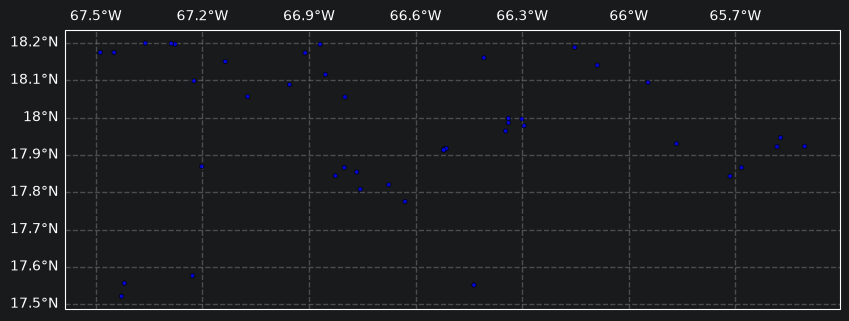

In [10]:
fig = plt.figure(figsize=(10, 10), linewidth=1)
ax = cat.plot_in_space(
    dot_smallest=0.1,
    dot_largest=10,
    dot_interpolation_power=0,
    dot_labels=False)

plt.show()

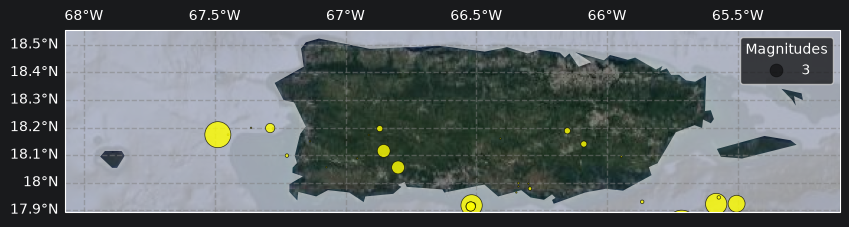

In [11]:
fig = plt.figure(figsize=(10, 10), linewidth=1)
ax = cat.plot_in_space(
    resolution='10m',
    include_map=True,
    country='Puerto Rico',
    dot_smallest=1,
    dot_largest=500,
    dot_interpolation_power=3,
    dot_labels=[1,2,3,4],
    color_dots = 'yellow')

plt.show()

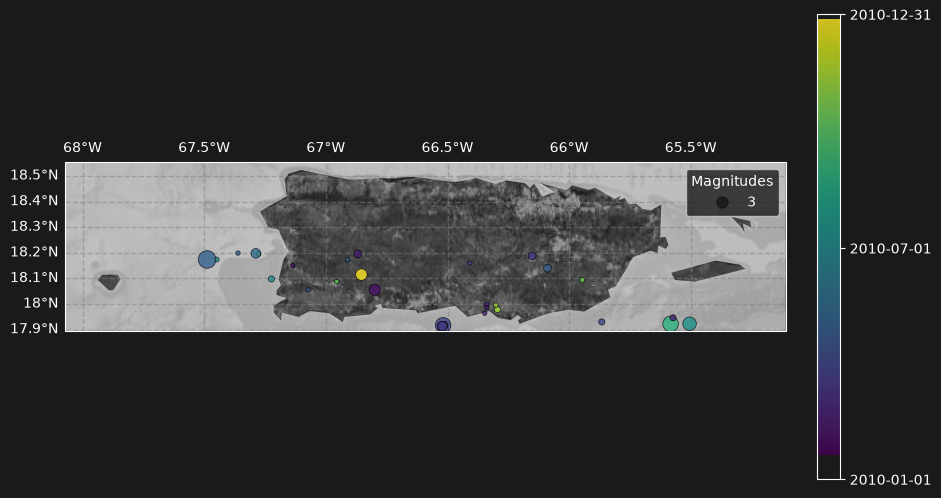

In [12]:
fig = plt.figure(figsize=(10, 10), linewidth=1)

ax = cat.plot_in_space(
    resolution='10m',
    include_map=True,
    country='Puerto Rico',
    color_dots=mdates.date2num(cat.time),
    color_map='Greys_r',
    dot_labels=[1, 2, 3, 4]
)

cbar = plt.colorbar(ax.collections[1], ax=ax, orientation='vertical', fraction=0.03, pad=0.04)


date_ticks = ["2010-01-01", "2010-07-01", "2010-12-31"]
date_ticks_num = mdates.date2num(date_ticks)
cbar.set_ticks(date_ticks_num)
cbar.ax.yaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))

plt.show()

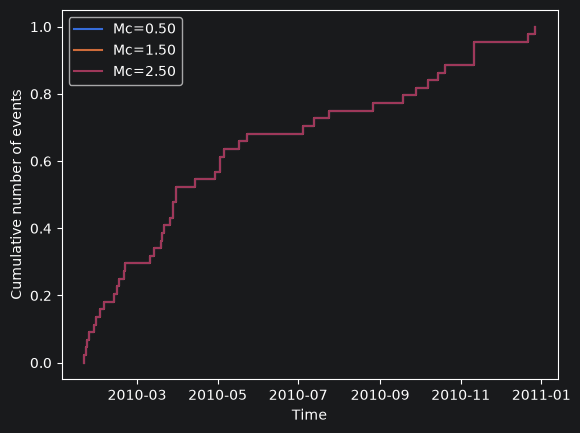

In [13]:
target_magnitudes = np.arange(0.5, 4.0, 1.0)

ax = cat.plot_cum_count(mcs=target_magnitudes)

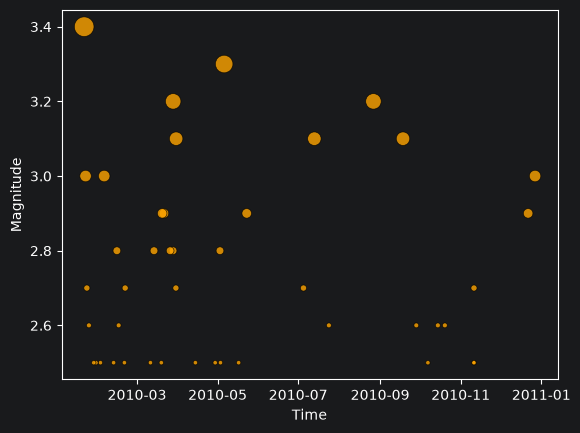

In [14]:
ax = cat.plot_mags_in_time(color_dots='orange')

Legend added to the plot.


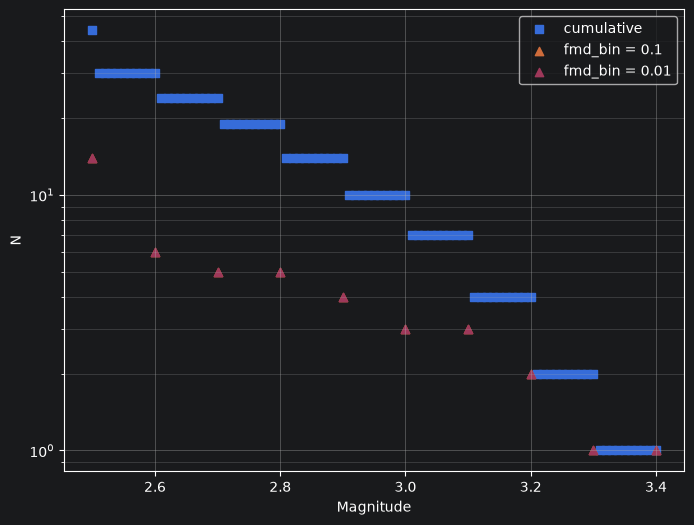

In [15]:
cat.bin_magnitudes(delta_m=0.01, inplace=True)

ax = plt.subplots(figsize=(8, 6))[1]

cat.plot_cum_fmd(ax=ax)

cat.plot_fmd(fmd_bin=0.1, ax=ax, grid=True, label='fmd_bin = 0.1')
cat.plot_fmd(fmd_bin=0.01, ax=ax, grid=True, label='fmd_bin = 0.01')

plt.show()

In [16]:
mc_maxc, _= cat.estimate_mc_maxc(fmd_bin=0.1)

print(f'Estimated Mc using MAXC: {mc_maxc}')
print(f'Mc (currently set catalog attribute): {cat.mc}')

Estimated Mc using MAXC: 2.7
Mc (currently set catalog attribute): 2.7


In [17]:
mc_stab, _ = cat.estimate_mc_b_stability(stop_when_passed=True)

print(f'Estimated Mc using MBS: {mc_stab}')

print(f'Mc (currently set catalog attribute): {cat.mc}')

return_vals: {'best_b_value': np.float64(1.6882830033055203), 'mcs_tested': [2.5], 'b_values_tested': [np.float64(1.6882830033055203)], 'diff_bs': [np.float64(0.331909198997358)]}
Estimated Mc using MBS: 2.5
Mc (currently set catalog attribute): 2.5


C:\Users\leyma\PycharmProjects\PythonProject\.venv\Lib\site-packages\seismostats\analysis\bvalue\base.py:119: UserWarning: No magnitudes in the lowest magnitude bin are present.Check if mc is chosen correctly.
  warnings.warn(


In [18]:
mc_kstest, dict = cat.estimate_mc_ks(
   mcs_test=np.arange(1.0, 3.0, 0.1),
    p_value_pass=0.1,
)

print(f"First Mc to pass the KS test: {mc_kstest:.2f}")
print(f"Associated beta value: {dict['best_b_value']:.2f}")


print(f'Mc (currently set catalog attribute): {cat.mc:.2f}')

C:\Users\leyma\PycharmProjects\PythonProject\.venv\Lib\site-packages\seismostats\analysis\estimate_mc.py:249: UserWarning: Mcs to test are not binned correctly. Test might fail because of this.
  warnings.warn("Mcs to test are not binned correctly. "


First Mc to pass the KS test: 2.60
Associated beta value: 1.58
Mc (currently set catalog attribute): 2.60


Legend added to the plot.


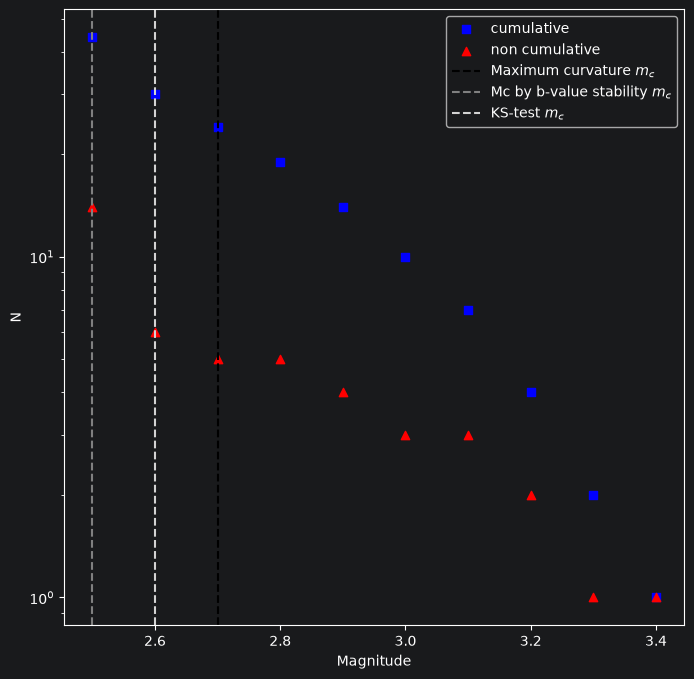

In [19]:
ax = plt.subplots(figsize=(8, 8))[1]

cat.plot_cum_fmd(fmd_bin=0.1, ax=ax, color='blue')
cat.plot_fmd(fmd_bin=0.1, ax=ax, color='red')

plt.axvline(mc_maxc, color='black', linestyle='--', label='Maximum curvature $m_c$')
plt.axvline(mc_stab, color='grey', linestyle='--', label='Mc by b-value stability $m_c$')
plt.axvline(mc_kstest, color='lightgrey', linestyle='--', label='KS-test $m_c$')

plt.legend()
plt.show()

In [20]:
b_estimator = cat.estimate_b()

print('Classical b-value', round(b_estimator.b_value,3))
print('Standard deviation', round(b_estimator.std,2))
print('Number of events used', b_estimator.n)

Classical b-value 1.579
Standard deviation 0.24
Number of events used 30


Legend added to the plot.


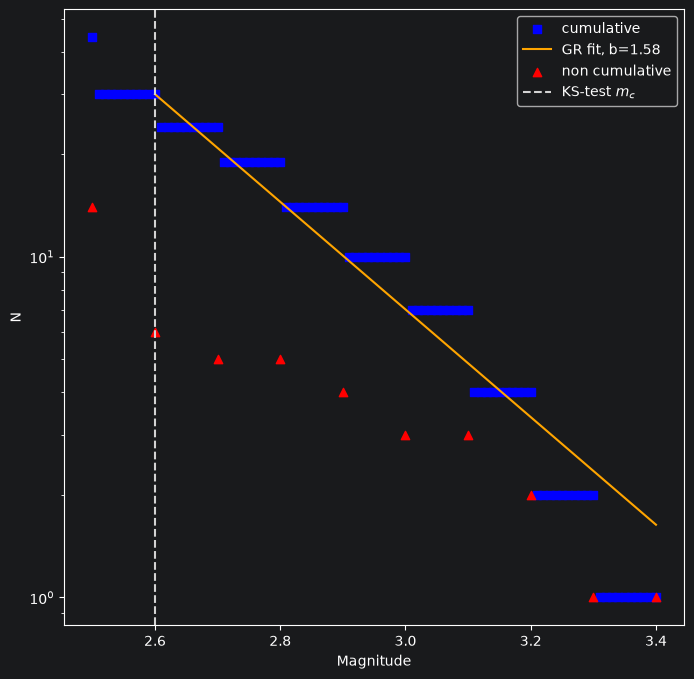

In [21]:
ax = plt.subplots(figsize=(8, 8))[1]
cat.plot_cum_fmd(color='blue',ax=ax, color_line = 'orange')
cat.plot_fmd(fmd_bin=0.1, ax=ax, color='red')

plt.axvline(mc_kstest, color='lightgrey', linestyle='--', label='KS-test $m_c$')
plt.legend()
plt.show()

In [22]:
from seismostats.analysis import BPositiveBValueEstimator
b_estimator = cat.estimate_b(method =BPositiveBValueEstimator)
print("b-positive:",round(cat.b_value,2))

b-positive: 1.56


<Axes: xlabel='Completeness magnitude $m_c$', ylabel='b-value'>

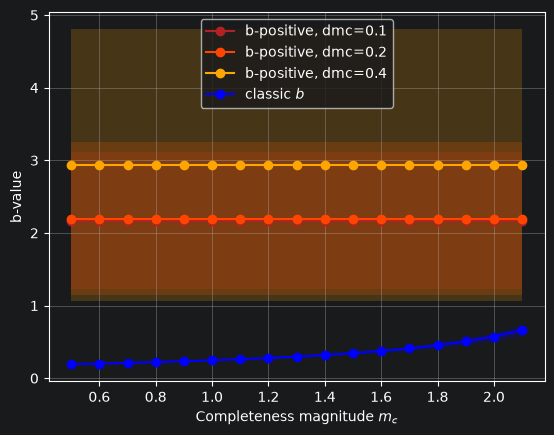

In [23]:
from seismostats.analysis import ClassicBValueEstimator, BPositiveBValueEstimator

mcs = np.arange(0.5, 2.2, 0.1)
ax = cat.plot_mc_vs_b(mcs, b_method=BPositiveBValueEstimator, dmc=0.1, color='firebrick', label='b-positive, dmc=0.1')
cat.plot_mc_vs_b(mcs, b_method=BPositiveBValueEstimator, dmc=0.2, ax=ax,  color='orangered', label='b-positive, dmc=0.2')
cat.plot_mc_vs_b(mcs, b_method=BPositiveBValueEstimator, dmc=0.4, ax=ax,  color='orange', label='b-positive, dmc=0.4')

cat.plot_mc_vs_b(mcs, b_method=ClassicBValueEstimator, ax =ax, color='blue', label='classic $b$')

Text(0.5, 0, 'Time')

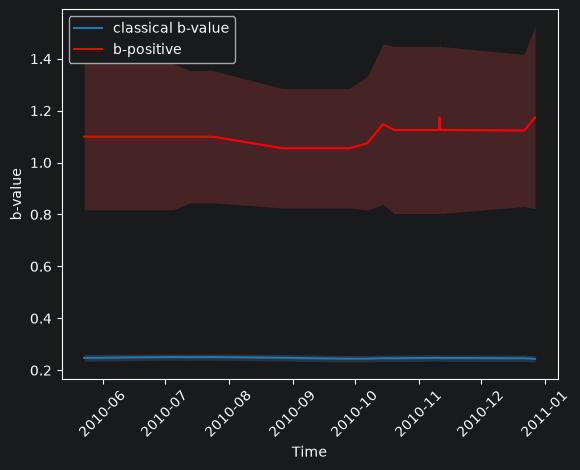

In [24]:
from seismostats.analysis import b_significant_1D
from seismostats.plots import plot_b_series_constant_nm, plot_b_significant_1D

mc = 1
delta_m = cat.delta_m
times = cat.time
mags = cat.magnitude
n_m = 30

ax = plot_b_series_constant_nm(mags, delta_m, mc, times, n_m=n_m, x_variable=times, color='#1f77b4', plot_technique='right', label='classical b-value')

ax = plot_b_series_constant_nm(mags, delta_m, mc, times, n_m=n_m, x_variable=times, color='red', plot_technique='right', label='b-positive', ax=ax, method=BPositiveBValueEstimator)

_ = plt.xticks(rotation=45)
ax.set_xlabel('Time')

In [25]:
p_threshold = 0.05
p, mac, mu_mac, std_mac = b_significant_1D(mags, mc, delta_m, times, n_m, x_variable=times, method= BPositiveBValueEstimator)
print('The p-value of a constant b-value hypothesis is {:.2f}'.format(p))

print('This is significantly larger than our threshold of {:.2f}. Therefore, we cannot reject the null-hypothesis'.format(p_threshold))

The p-value of a constant b-value hypothesis is nan
This is significantly larger than our threshold of 0.05. Therefore, we cannot reject the null-hypothesis


C:\Users\leyma\PycharmProjects\PythonProject\.venv\Lib\site-packages\seismostats\analysis\b_significant.py:396: UserWarning: n_m is too large - less than three subsamples are created,returning NaNs.
  warnings.warn(


C:\Users\leyma\PycharmProjects\PythonProject\.venv\Lib\site-packages\seismostats\analysis\bvalue\base.py:119: UserWarning: No magnitudes in the lowest magnitude bin are present.Check if mc is chosen correctly.
  warnings.warn(
C:\Users\leyma\PycharmProjects\PythonProject\.venv\Lib\site-packages\seismostats\plots\statistical.py:330: UserWarning: Not enough events to estimate significance.
  warnings.warn("Not enough events to estimate significance.")
C:\Users\leyma\PycharmProjects\PythonProject\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:588: RuntimeWarning: Mean of empty slice
  avg = a.mean(axis, **keepdims_kw)
C:\Users\leyma\PycharmProjects\PythonProject\.venv\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\leyma\PycharmProjects\PythonProject\.venv\Lib\site-packages\seismostats\analysis\bvalue\utils.py:99: RuntimeWarning: invalid value encountered in sqrt
  np.log(10) 

<Axes: xlabel='$n_m$', ylabel='MAC'>

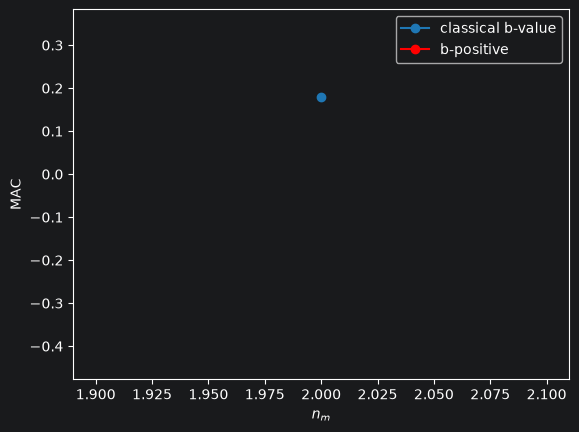

In [26]:
srt = np.argsort(times)
mags = mags[srt]
times = times[srt]

ax = plot_b_significant_1D(
    mags, mc, delta_m, times, x_variable=times, color = '#1f77b4', label='classical b-value')

plot_b_significant_1D(
    mags, mc, delta_m,  times, x_variable=times, method=BPositiveBValueEstimator, color = 'red', ax = ax, label='b-positive')


In [29]:
from seismostats.utils import simulate_magnitudes_binned


n = 500
b_value = 1.5
delta_m = 0.05
mc = 3
dmc = 0.3

mags = simulate_magnitudes_binned(n, b_value, mc, delta_m)
cat = pd.DataFrame({'magnitude': mags})
cat = Catalog(cat)
cat.delta_m = delta_m
cat.mc = mc


cat.estimate_b()
print('Estimated b-value of the synthetic catalog:', round(cat.b_value,2))

Estimated b-value of the synthetic catalog: 1.48


Legend added to the plot.


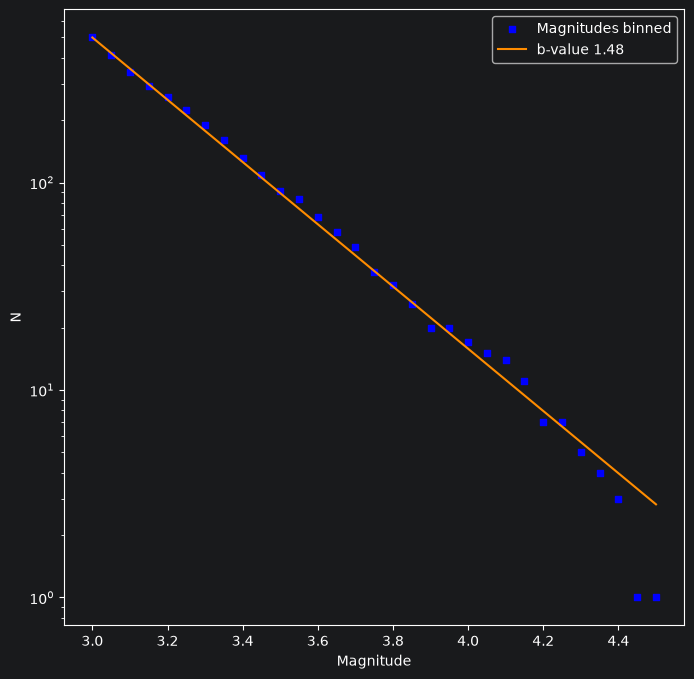

In [30]:
ax = plt.subplots(figsize=(8, 8))[1]

cat.plot_cum_fmd(ax=ax, b_value=b_value,
             color='blue', color_line = 'darkorange', label='Magnitudes binned', label_line = f'b-value {cat.b_value:.2f}', size=20)

plt.show()

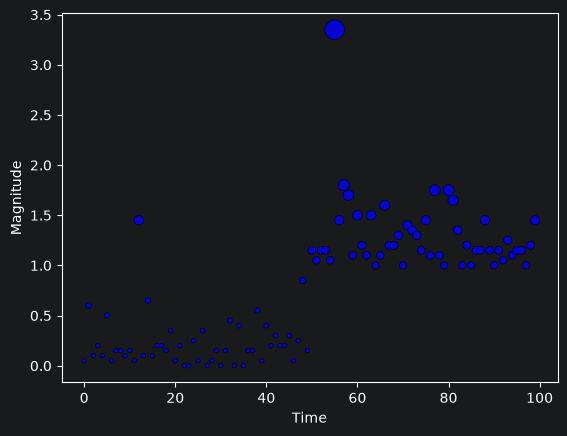

In [31]:
from seismostats.utils import simulate_magnitudes_binned
from seismostats.plots import plot_mags_in_time
n = 100
b_value = 1.5
delta_m = 0.05
mc = np.zeros(n)
mc[n//2:] = 1
mags = simulate_magnitudes_binned(n, b_value, mc, delta_m)
ax = plot_mags_in_time(np.arange(len(mags)), mags)